# Marketing A/B Testing Analysis

## Project Overview
This project evaluates the effectiveness of an advertising campaign by comparing conversion rates between two groups:
- **Ad Group:** Users exposed to the advertisement.
- **PSA Group (Control):** Users exposed to a public service announcement.

## Business Objective
Determine whether the advertisement generates a statistically significant improvement in conversion rates compared with the control group.

## Key Questions
- What is the conversion rate for each group?
- Is the difference statistically significant?
- What is the conversion lift associated with the advertisement?
- What is the estimated impact of rolling out the advertisement to all users?

## Tools & Techniques
Python, Pandas, NumPy, Matplotlib, SciPy, and Statsmodels.

## Analysis Workflow
1. Data Loading and Audit
2. Data Preparation
3. Conversion Rate Analysis
4. Hypothesis Testing
5. Lift Estimation and Confidence Intervals
6. Business Impact and Recommendations

## Stage 1: Import Libraries

Import the essential Python libraries for data manipulation, statistical hypothesis testing, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

## Stage 2: Load Dataset

Load the Marketing A/B Testing dataset into a Pandas DataFrame for inspection and analysis.

In [2]:
df = pd.read_csv(r"D:\Ahmed\Education\Elevvo Internship\Tasks\Task 10\data\marketing_AB.csv")

df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


## Stage 3: Data Audit

Inspect the dataset structure, data types, missing values, duplicate records, and column names to assess data quality before analysis.

In [3]:
print("Dataset Shape:", df.shape)
print("\nDataset Info:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (588101, 7)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Unnamed: 0     588101 non-null  int64 
 1   user id        588101 non-null  int64 
 2   test group     588101 non-null  object
 3   converted      588101 non-null  bool  
 4   total ads      588101 non-null  int64 
 5   most ads day   588101 non-null  object
 6   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(4), object(2)
memory usage: 27.5+ MB

Missing Values:
Unnamed: 0       0
user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

Duplicate Rows: 0

Column Names:
['Unnamed: 0', 'user id', 'test group', 'converted', 'total ads', 'most ads day', 'most ads hour']


### Data Quality Summary

- **Total Records:** 588,101
- **Total Columns:** 7
- **Missing Values:** None
- **Duplicate Rows:** None
- **Data Types:** Boolean, Integer, and Object

The dataset contains no missing values or duplicate rows. Further validation is required to assess group allocation and prepare the data for statistical analysis.

## Stage 4: Data Preparation

Standardize column names, remove the unnecessary index column, and validate the experiment groups before calculating conversion rates.by standardizing column names, removing unnecessary columns, and validating the experiment groups.

In [4]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df = df.drop(columns=["unnamed:_0"])

df["test_group"].value_counts()

test_group
ad     564577
psa     23524
Name: count, dtype: int64

## Stage 5: Conversion Rate Analysis

Calculate and compare the conversion rates of the Ad and PSA groups.

- **Ad Group:** Users exposed to the advertisement.
- **PSA Group:** Control group exposed to a public service announcement.

The conversion rate is calculated as the number of converted users divided by the total number of users in each group.

In [5]:
summary = df.groupby("test_group")["converted"].agg(["count", "sum", "mean"])
summary.columns = ["users", "conversions", "conversion_rate"]
summary["conversion_rate_%"] = summary["conversion_rate"] * 100

summary

,users,conversions,conversion_rate,conversion_rate_%
test_group,,,,
ad,564577,14423,0.025547,2.554656
psa,23524,420,0.017854,1.785411


## Stage 6: Hypothesis Testing

Use a two-proportion Z-test to determine whether the difference in conversion rates between the Ad and PSA groups is statistically significant.

### Hypotheses
- **Null Hypothesis (H₀):** The conversion rates of the two groups are equal.
- **Alternative Hypothesis (H₁):** The conversion rates of the two groups are different.

**Significance Level (α):** 0.05  
**Confidence Level:** 95%

In [8]:
ad = df[df["test_group"] == "ad"]["converted"].astype(int)
psa = df[df["test_group"] == "psa"]["converted"].astype(int)

z_stat, p_value = proportions_ztest(
    [ad.sum(), psa.sum()],
    [ad.count(), psa.count()]
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Result: Reject the null hypothesis.")
else:
    print("Result: Fail to reject the null hypothesis.")

Z-statistic: 7.3701
P-value: 0.000000
Result: Reject the null hypothesis.


### Hypothesis Test Interpretation

The p-value is compared with the significance level of 0.05.

- If **p-value < 0.05**, reject the null hypothesis. The observed conversion rates are statistically significantly different.
- If **p-value ≥ 0.05**, fail to reject the null hypothesis. There is insufficient evidence of a statistically significant difference.

Statistical significance alone does not establish the practical or business importance of the difference.

## Stage 7: Conversion Lift & Confidence Interval

This stage measures the improvement in conversion rate for the Ad group compared to the PSA group.

* **Absolute Lift:** Difference between the two conversion rates.
* **Relative Lift:** Percentage improvement in the Ad group's conversion rate.
* **95% Confidence Interval:** Estimates the plausible range for the difference in conversion rates.


In [9]:
import numpy as np
from scipy.stats import norm

ad = df[df["test_group"] == "ad"]["converted"]
psa = df[df["test_group"] == "psa"]["converted"]

n1, n2 = len(ad), len(psa)
p1, p2 = ad.mean(), psa.mean()

lift = p1 - p2
relative_lift = lift / p2 * 100

se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
ci_low = lift - norm.ppf(0.975) * se
ci_high = lift + norm.ppf(0.975) * se

print(f"Ad Conversion Rate: {p1:.4%}")
print(f"PSA Conversion Rate: {p2:.4%}")
print(f"Absolute Lift: {lift:.4%}")
print(f"Relative Lift: {relative_lift:.2f}%")
print(f"95% CI: ({ci_low:.4%}, {ci_high:.4%})")

Ad Conversion Rate: 2.5547%
PSA Conversion Rate: 1.7854%
Absolute Lift: 0.7692%
Relative Lift: 43.09%
95% CI: (0.5951%, 0.9434%)


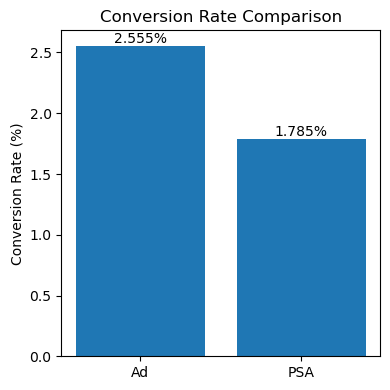

In [15]:
import matplotlib.pyplot as plt

rates = [p1 * 100, p2 * 100]
groups = ["Ad", "PSA"]

plt.figure(figsize=(4, 4))
plt.bar(groups, rates)
plt.ylabel("Conversion Rate (%)")
plt.title("Conversion Rate Comparison")
plt.bar_label(plt.gca().containers[0], fmt="%.3f%%")
plt.tight_layout()
plt.show()

## Stage 8: Business Impact Analysis

This stage evaluates the practical significance of the observed conversion improvement and its potential impact on advertising performance.

The results will be interpreted in terms of conversion improvement, campaign costs, and potential profitability.

In [10]:
print(f"Ad Conversion Rate: {p1:.4%}")
print(f"PSA Conversion Rate: {p2:.4%}")
print(f"Relative Improvement: {relative_lift:.2f}%")

if p1 > p2:
    print("Business Insight: The Ad group achieved a higher conversion rate.")
else:
    print("Business Insight: The Ad group did not outperform the PSA group.")

Ad Conversion Rate: 2.5547%
PSA Conversion Rate: 1.7854%
Relative Improvement: 43.09%
Business Insight: The Ad group achieved a higher conversion rate.


## Stage 9: Final Results & Business Recommendations

### Key Findings

* The two-proportion Z-test identified a statistically significant difference between the Ad and PSA conversion rates.
* The Ad group achieved a relative conversion lift of 43.09%.
* The absolute conversion rate difference was 0.7692 percentage points.
* The 95% confidence interval ranged from 0.5951 to 0.9434 percentage points.

### Business Recommendations

* Evaluate advertising costs and cost per conversion before increasing campaign spending.
* Monitor conversion performance across audience segments to identify optimization opportunities.
* Assess revenue and profitability before making budget allocation decisions.

### Conclusion

The results provide strong statistical evidence that the Ad group outperformed the PSA group in conversion rate. Further financial analysis is required to determine whether the improvement translates into profitable business outcomes.


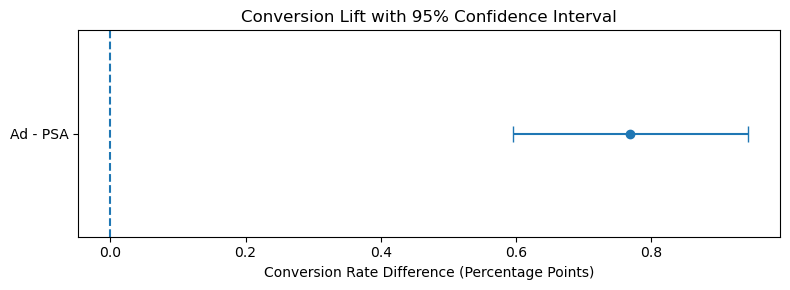

In [17]:
lift_pct = lift * 100
low_pct = ci_low * 100
high_pct = ci_high * 100

plt.figure(figsize=(8, 3))

plt.errorbar(
    lift_pct, 0,
    xerr=[[lift_pct - low_pct], [high_pct - lift_pct]],
    fmt="o",
    capsize=6
)

plt.axvline(0, linestyle="--")
plt.yticks([0], ["Ad - PSA"])
plt.xlabel("Conversion Rate Difference (Percentage Points)")
plt.title("Conversion Lift with 95% Confidence Interval")
plt.tight_layout()
plt.show()